# 호텔 예약 취소 예측: 데이터 확인
1. 범주형을 정수로 바꿔 상관계수 보기
2. 이상치 확인하기
3. 이상치 제거

In [1]:
!pip install -q koreanize-matplotlib

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.9/7.9 MB 18.9 MB/s eta 0:00:00


In [2]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
import matplotlib.pyplot as plt
import seaborn as sns
import koreanize_matplotlib
from sklearn.metrics import ConfusionMatrixDisplay
from sklearn.metrics import confusion_matrix
from sklearn.tree import plot_tree
from scipy.stats import uniform, randint
from sklearn.model_selection import RandomizedSearchCV

In [3]:
from google.colab import drive
drive.mount('/content/drive')

url = "/content/drive/MyDrive/Colab Notebooks/bigdata/"
df = pd.read_csv(url+"hotel_bookings.csv")

df.sample(10)

Mounted at /content/drive


,hotel,lead_time,arrival_month,adults,children,babies,country,market_segment,deposit_type,customer_type,adr,previous_cancellations,special_requests,is_canceled
139,Resort Hotel,68,Sep,3,0.0,0,USA,Corporate,No Deposit,Contract,62.0,3,4,1
39,Resort Hotel,280,Jul,2,0.0,0,USA,Agent,No Deposit,Transient,304.0,2,3,1
149,City Hotel,219,May,4,1.0,0,CHN,Online,No Deposit,Group,78.0,2,3,1
212,Resort Hotel,195,Oct,2,1.0,0,GBR,Agent,No Deposit,Transient,62.0,5,0,1
380,City Hotel,34,Jan,3,2.0,0,JPN,Online,Non Refund,Contract,249.0,5,4,0
447,City Hotel,111,Mar,1,0.0,0,USA,Offline,Refundable,Group,331.0,3,1,1
325,City Hotel,190,Mar,2,1.0,0,GBR,Online,Refundable,Transient,278.0,3,4,1
197,City Hotel,284,Apr,3,1.0,0,FRA,Agent,No Deposit,Transient,345.0,1,2,1
422,City Hotel,84,Jan,2,1.0,0,GBR,Agent,Refundable,Transient,186.0,2,1,0
184,Resort Hotel,151,Nov,1,0.0,0,JPN,Online,Refundable,Group,147.0,2,2,1


In [5]:
df.info()   # 자료형과 결측치 확인

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 457 entries, 0 to 456
Data columns (total 14 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   hotel                   457 non-null    object 
 1   lead_time               457 non-null    int64  
 2   arrival_month           457 non-null    object 
 3   adults                  457 non-null    int64  
 4   children                449 non-null    float64
 5   babies                  457 non-null    int64  
 6   country                 450 non-null    object 
 7   market_segment          457 non-null    object 
 8   deposit_type            453 non-null    object 
 9   customer_type           457 non-null    object 
 10  adr                     452 non-null    float64
 11  previous_cancellations  457 non-null    int64  
 12  special_requests        457 non-null    int64  
 13  is_canceled             457 non-null    int64  
dtypes: float64(2), int64(6), object(6)
memory 

## 1. 범주형을 정수로 바꿔 상관계수 보기
- 월은 순서가 있으니 직접 1~12로 바꿉니다.
- 나머지 범주형은 알파벳 순서대로 0, 1, 2 … 번호가 붙습니다. 빈 칸은 -1이 됩니다.

In [6]:
data = df.copy()
month = {'Jan': 1, 'Feb': 2, 'Mar': 3, 'Apr': 4, 'May': 5, 'Jun': 6,
         'Jul': 7, 'Aug': 8, 'Sep': 9, 'Oct': 10, 'Nov': 11, 'Dec': 12}
data['arrival_month'] = data['arrival_month'].map(month)


cat_cols = ['hotel', 'country', 'market_segment', 'deposit_type', 'customer_type']
for col in cat_cols:
    data[col] = data[col].astype('category')
    print(col, dict(enumerate(data[col].cat.categories)))
    data[col] = data[col].cat.codes

data.head()

hotel {0: 'City Hotel', 1: 'Resort Hotel'}
country {0: 'CHN', 1: 'FRA', 2: 'GBR', 3: 'JPN', 4: 'KOR', 5: 'USA'}
market_segment {0: 'Agent', 1: 'Corporate', 2: 'Offline', 3: 'Online'}
deposit_type {0: 'No Deposit', 1: 'Non Refund', 2: 'Refundable'}
customer_type {0: 'Contract', 1: 'Group', 2: 'Transient'}


,hotel,lead_time,arrival_month,adults,children,babies,country,market_segment,deposit_type,customer_type,adr,previous_cancellations,special_requests,is_canceled
0,1,263,12,2,0.0,0,4,3,2,2,227.0,0,1,0
1,0,282,2,2,0.0,0,2,0,0,0,328.0,1,2,1
2,1,26,6,2,1.0,0,1,1,2,1,195.0,5,2,1
3,1,225,2,2,0.0,0,1,2,0,1,1500.0,2,4,1
4,1,276,2,2,2.0,0,4,1,0,1,111.0,1,2,1


In [8]:
corr = data.corr()
corr['is_canceled'].sort_values(ascending=False).round(2)

,is_canceled
is_canceled,1.00
previous_cancellations,0.38
lead_time,0.25
customer_type,0.05
country,0.03
adr,0.01
children,-0.02
adults,-0.04
babies,-0.04
market_segment,-0.05


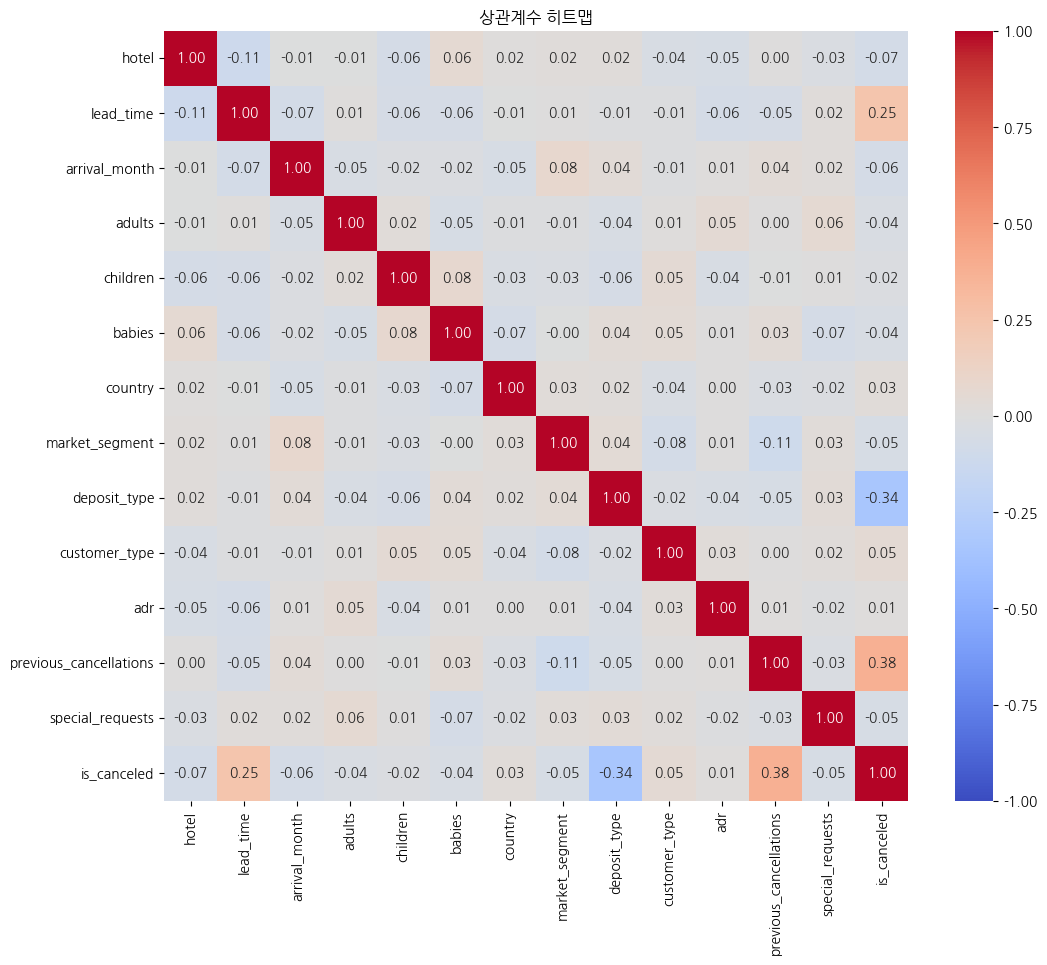

In [10]:
plt.figure(figsize=(12, 10))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1)
plt.title('상관계수 히트맵')
plt.show()

##  이상치 확인하기

In [11]:
num_cols = ['lead_time', 'adults', 'children', 'babies', 'adr',
            'previous_cancellations', 'special_requests']

#
df[num_cols].describe()

,lead_time,adults,children,babies,adr,previous_cancellations,special_requests
count,457.000000,457.000000,449.000000,457.000000,452.000000,457.000000,457.000000
mean,181.516411,2.317287,0.389755,0.045952,229.280973,2.595186,2.048140
std,131.235593,1.364488,0.669476,0.209610,270.274359,1.679409,1.385182
min,0.000000,1.000000,0.000000,0.000000,-50.000000,0.000000,0.000000
25%,95.000000,2.000000,0.000000,0.000000,143.000000,1.000000,1.000000
50%,176.000000,2.000000,0.000000,0.000000,225.000000,3.000000,2.000000
75%,258.000000,3.000000,1.000000,0.000000,281.250000,4.000000,3.000000
max,1500.000000,20.000000,2.000000,1.000000,5000.000000,5.000000,4.000000


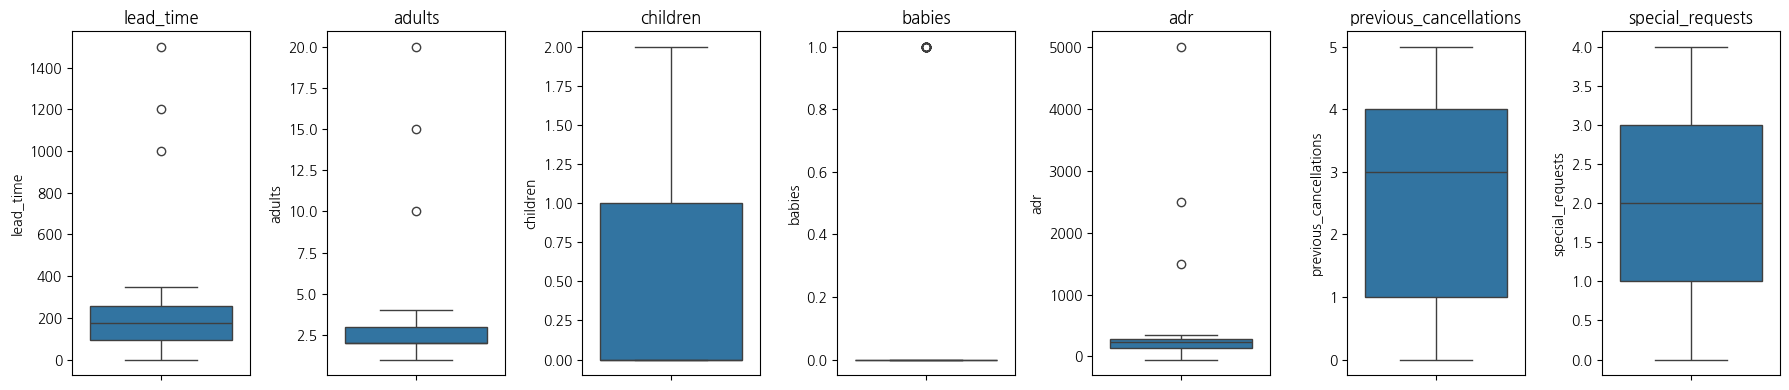

In [58]:
fig, axes = plt.subplots(1, 7, figsize=(18, 4))
for ax, col in zip(axes, num_cols):
    sns.boxplot(y=df[col], ax=ax)
    ax.set_title(col)
plt.tight_layout()
plt.show()

In [59]:
for col in num_cols:
    Q1 = df[col].quantile(0.25)          # 하위 25%
    Q3 = df[col].quantile(0.75)          # 상위 25%
    IQR = Q3 - Q1
    low, high = Q1 - 1.5 * IQR, Q3 + 1.5 * IQR
    out = df[(df[col] < low) | (df[col] > high)][col]
    print(f'{col}: 정상범위 {low:.0f} ~ {high:.0f}, 이상치 {len(out)}개 → {sorted(out.tolist())}')

lead_time: 정상범위 -150 ~ 502, 이상치 3개 → [999, 1200, 1500]
adults: 정상범위 0 ~ 4, 이상치 3개 → [10, 15, 20]
children: 정상범위 -2 ~ 2, 이상치 0개 → []
babies: 정상범위 0 ~ 0, 이상치 21개 → [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1]
adr: 정상범위 -64 ~ 489, 이상치 3개 → [1500.0, 2500.0, 5000.0]
previous_cancellations: 정상범위 -4 ~ 8, 이상치 0개 → []
special_requests: 정상범위 -2 ~ 6, 이상치 0개 → []


In [15]:
"""print('제거 전:', len(df))
df_clean = df[(df['lead_time'] <= 365) &
              (df['adults'] <= 6) &
              (df['adr'].between(0, 1000) | df['adr'].isna())]
print('제거 후:', len(df_clean))

제거 전: 457
제거 후: 447


In [60]:
data = df_clean.copy()
data['arrival_month'] = data['arrival_month'].map(month)
for col in cat_cols:
    data[col] = data[col].astype('category').cat.codes

X = data.drop(columns=["is_canceled"])   #
y = data["is_canceled"]

X = X.fillna(0)

In [61]:
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.3,random_state=123 )

print(X_train.shape, X_test.shape, y_train.shape, y_test.shape)
print("학습 데이터 형태:", X_train.shape)
print("테스트 데이터 형태:", X_test.shape)

(312, 13) (135, 13) (312,) (135,)
학습 데이터 형태: (312, 13)
테스트 데이터 형태: (135, 13)


In [62]:
from sklearn.preprocessing import LabelEncoder
le = LabelEncoder()
cloumns=['is_canceled']
le.fit(y_train)
y_train=le.transform(y_train)
y_test=le.transform(y_test)

In [63]:
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)

In [64]:
import pandas as pd
from sklearn.tree import DecisionTreeClassifier

dt = DecisionTreeClassifier(max_depth=5, random_state=42)
dt.fit(X_train, y_train)

print("학습 정확도:", dt.score(X_train, y_train))
print("테스트 정확도:", dt.score(X_test, y_test))

학습 정확도: 0.9935897435897436
테스트 정확도: 0.9851851851851852


In [65]:
print(dt.score(X_train,y_train))

0.9935897435897436


In [66]:
print(dt.score(X_test,y_test))

0.9851851851851852


In [67]:
pr = dt.predict(X_test)
cm = confusion_matrix(y_test, pr)
print(cm)

[[41  1]
 [ 1 92]]


In [68]:
pr_train = dt.predict(X_train)
cm = confusion_matrix(y_train, pr_train)
print(cm)

[[110   0]
 [  2 200]]


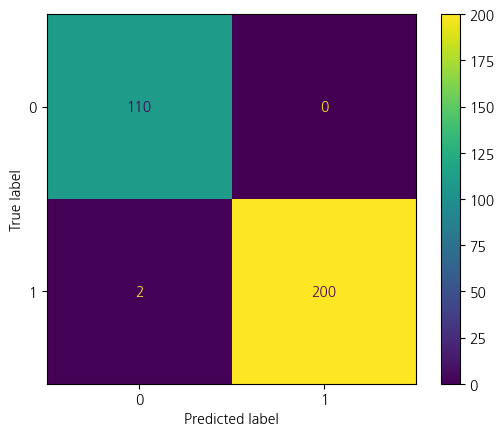

In [69]:
ConfusionMatrixDisplay.from_predictions(y_train, pr_train)
plt.show()

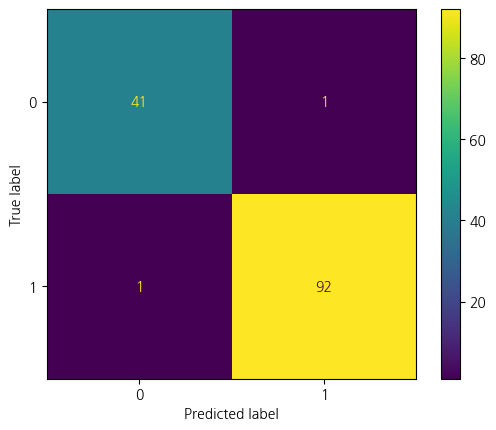

In [70]:
ConfusionMatrixDisplay.from_predictions(y_test, pr)
plt.show()

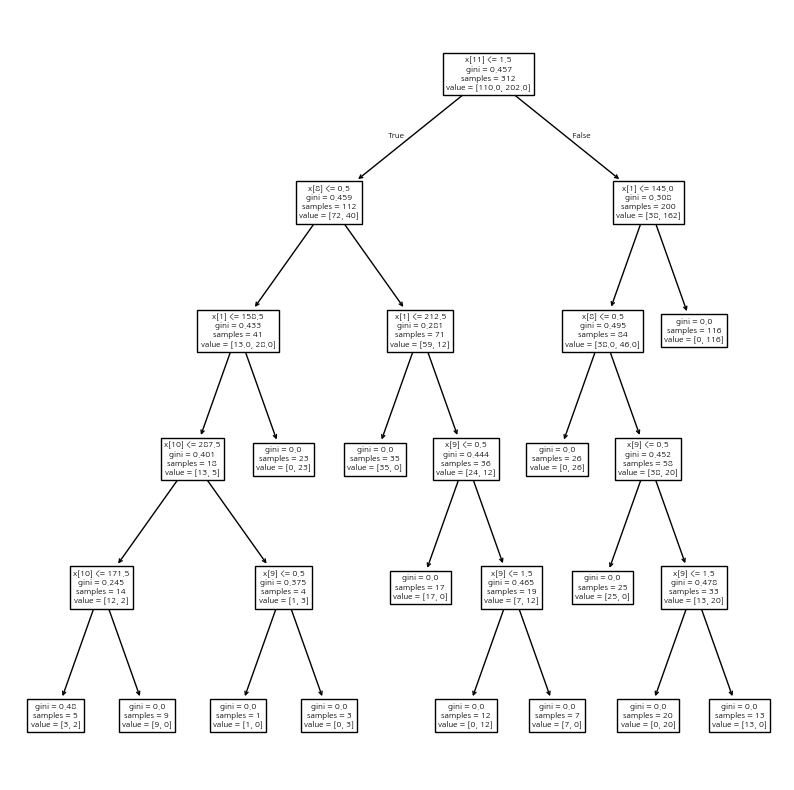

In [71]:
plt.figure(figsize=(10,10))
plot_tree(dt,max_depth=5)
plt.show()

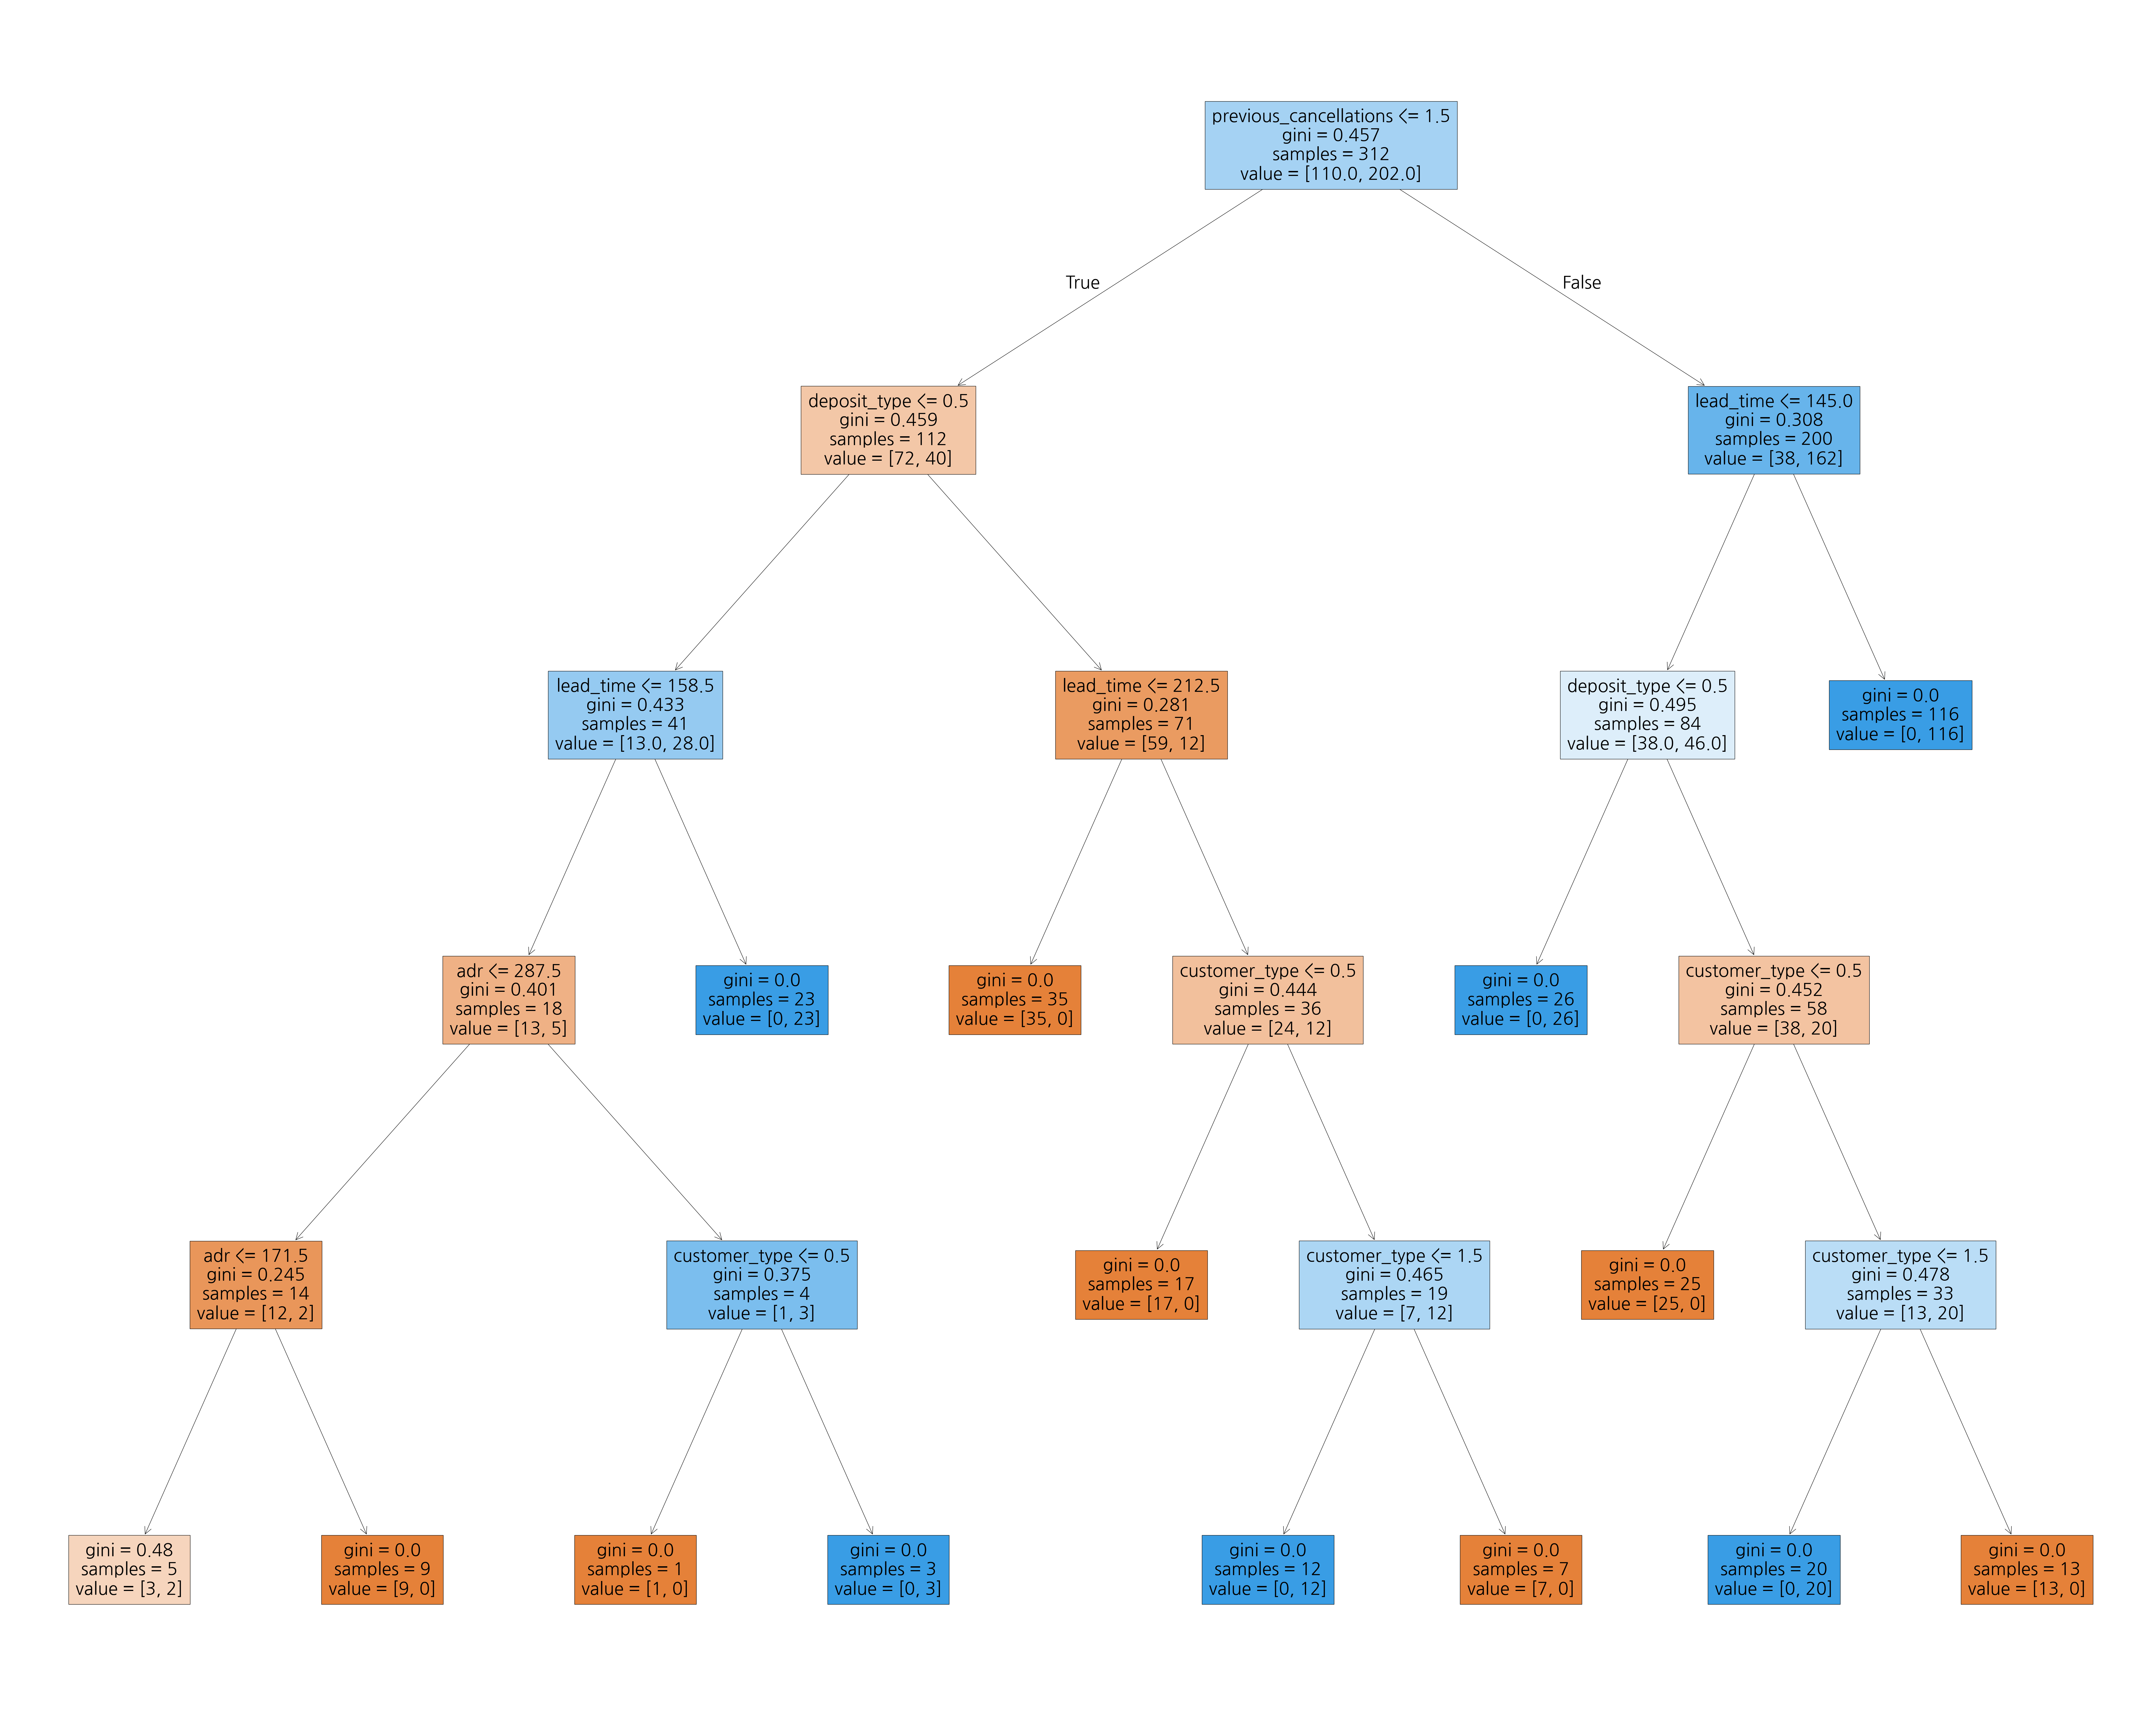

In [72]:
plt.figure(figsize=(100,80))
plot_tree(
    dt, max_depth=5,
    filled=True,
    feature_names=list(X_train.columns)
)
plt.show()

In [31]:
print(dt.feature_importances_)

[0.         0.24578333 0.         0.         0.         0.
 0.         0.         0.20809638 0.31211209 0.02372408 0.21028412
 0.        ]


#**교차검증**

In [32]:
sub_input, val_input, sub_target, val_target = train_test_split(
    X_train, y_train, test_size=0.3, random_state=42)
print(sub_input.shape, val_input.shape, sub_target.shape, val_target.shape)

(218, 13) (94, 13) (218,) (94,)


In [33]:
cross=DecisionTreeClassifier(max_depth=5,random_state=42)
cross.fit(sub_input,sub_target)

DecisionTreeClassifier(max_depth=5, random_state=42)

In [34]:
# [수정] dt → cross (교차검증용으로 학습한 모델로 평가)
print(cross.score(sub_input,sub_target))

1.0


In [35]:
# [수정] dt → cross (교차검증용으로 학습한 모델로 평가)
print(cross.score(val_input,val_target))

1.0


In [36]:
from sklearn.model_selection import cross_validate

scs =cross_validate(cross,X_train,y_train)
print(scs)

{'fit_time': array([0.00897574, 0.00421834, 0.0038507 , 0.00350714, 0.00376654]), 'score_time': array([0.0066731 , 0.00251341, 0.00209951, 0.00216317, 0.00173068]), 'test_score': array([1.        , 0.98412698, 1.        , 0.90322581, 0.93548387])}


In [37]:
import numpy as np

print(np.mean(scs['test_score']))

0.9645673323092678


In [38]:
from sklearn.model_selection import StratifiedKFold

scs=cross_validate(cross,X_train,y_train, cv=StratifiedKFold())
print(np.mean(scs['test_score']))

0.9645673323092678


#**5-Fold 교차 검증**

In [39]:
# [수정] X_train_en/X_test_en은 정의된 적 없음 → X_train/X_test
splitter = StratifiedKFold(shuffle=True, random_state=42)
scs=cross_validate(cross,X_train,y_train,cv=splitter)
print(np.mean(scs['test_score']))

0.9743471582181259


In [40]:
# [수정] X_train_en/X_test_en은 정의된 적 없음 → X_train/X_test
splitter = StratifiedKFold(n_splits=45,shuffle=True, random_state=42)
scs=cross_validate(cross,X_train,y_train,cv=splitter)
print(np.mean(scs['test_score']))

0.9714285714285714


#**GridSearchCV**

In [41]:
from sklearn.model_selection import GridSearchCV

params = {
    'max_depth': [3, 5, 7, 9, None],
    'min_samples_leaf': [1, 5, 10, 20],
    'criterion': ['gini', 'entropy'],
}

In [42]:
# [수정] X_train_en/X_test_en은 정의된 적 없음 → X_train/X_test
gs = GridSearchCV(
    DecisionTreeClassifier(random_state=42),
    params,
    cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=42),
    scoring='accuracy'
)
gs.fit(X_train, y_train)

GridSearchCV(cv=StratifiedKFold(n_splits=5, random_state=42, shuffle=True),
             estimator=DecisionTreeClassifier(random_state=42),
             param_grid={'criterion': ['gini', 'entropy'],
                         'max_depth': [3, 5, 7, 9, None],
                         'min_samples_leaf': [1, 5, 10, 20]},
             scoring='accuracy')

In [43]:
print(gs.best_params_)
print(f"교차검증 정확도:{round(gs.best_score_, 2)}")

{'criterion': 'entropy', 'max_depth': 7, 'min_samples_leaf': 1}
교차검증 정확도:0.98


In [44]:
# [수정] X_train_en/X_test_en은 정의된 적 없음 → X_train/X_test
gs_model = gs.best_estimator_
print(gs_model.score(X_train, y_train))

1.0


In [45]:
print(gs_model.score(X_train, y_train))

1.0


In [46]:
# [수정] X_train_en/X_test_en은 정의된 적 없음 → X_train/X_test
print(gs_model.score(X_test, y_test))

0.9851851851851852


In [47]:
print(gs_model.score(X_test, y_test))

0.9851851851851852


In [48]:
print(gs.cv_results_['mean_test_score'])

[0.86856119 0.86856119 0.86856119 0.84285714 0.97434716 0.94854071
 0.93261649 0.84935996 0.97112135 0.94854071 0.93261649 0.84935996
 0.97112135 0.94854071 0.93261649 0.84935996 0.97112135 0.94854071
 0.93261649 0.84935996 0.86856119 0.86856119 0.86856119 0.84285714
 0.97757296 0.95821813 0.92616487 0.83968254 0.98074757 0.95821813
 0.92616487 0.83968254 0.98074757 0.95821813 0.92616487 0.83968254
 0.98074757 0.95821813 0.92616487 0.83968254]


#**RandomizedSearchCV**

In [49]:
# [수정] 후보가 전부 목록이면 그리드서치와 같음 → 범위(분포)로 지정
# params = {
#     'max_depth': [3, 5, 7, 9, None],
#     'min_samples_leaf': [1, 5, 10, 20],
#     'criterion': ['gini', 'entropy']
# }
params = {
    'max_depth': randint(3, 20),                      # 3 ~ 19 정수
    'min_samples_split': randint(2, 50),              # 2 ~ 49 정수
    'min_samples_leaf': randint(1, 30),               # 1 ~ 29 정수
    'min_impurity_decrease': uniform(0.0001, 0.001),
    'criterion': ['gini', 'entropy'],
}

In [50]:
ugen = uniform(0, 1)
ugen.rvs(10)

array([0.63820392, 0.49167811, 0.15080756, 0.13187573, 0.02877078,
       0.84630355, 0.47785531, 0.33358057, 0.40884954, 0.16037175])

In [51]:
# [수정] X_train_en/X_test_en은 정의된 적 없음 → X_train/X_test
from sklearn.model_selection import RandomizedSearchCV

rs = RandomizedSearchCV(DecisionTreeClassifier(random_state=42), params,
                        n_iter=50, cv=5, random_state=42)
rs.fit(X_train, y_train)

RandomizedSearchCV(cv=5, estimator=DecisionTreeClassifier(random_state=42),
                   n_iter=50,
                   param_distributions={'criterion': ['gini', 'entropy'],
                                        'max_depth': <scipy.stats._distn_infrastructure.rv_discrete_frozen object at 0x7b66c57d0440>,
                                        'min_impurity_decrease': <scipy.stats._distn_infrastructure.rv_continuous_frozen object at 0x7b66c57d06e0>,
                                        'min_samples_leaf': <scipy.stats._distn_infrastructure.rv_discrete_frozen object at 0x7b66bf74e710>,
                                        'min_samples_split': <scipy.stats._distn_infrastructure.rv_discrete_frozen object at 0x7b66bf74e350>},
                   random_state=42)

In [52]:
print(rs.best_params_)

{'criterion': 'gini', 'max_depth': 19, 'min_impurity_decrease': np.float64(0.000366781014275285), 'min_samples_leaf': 2, 'min_samples_split': 3}


In [53]:
print(np.max(rs.cv_results_['mean_test_score']))

0.9645673323092678


In [54]:
random = rs.best_estimator_

print(random.score(X_test, y_test))

0.9777777777777777


In [55]:
# [수정] X_train_en/X_test_en은 정의된 적 없음 → X_train/X_test
print(random.score(X_test, y_test))

0.9777777777777777


In [56]:
print(random.score(X_train, y_train))

0.9935897435897436


In [57]:
# [수정] X_train_en/X_test_en은 정의된 적 없음 → X_train/X_test
print(random.score(X_train, y_train))

0.9935897435897436
